In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

## 1. Análisis Exploratorio

In [145]:
# abrimos el archivo y vemos el tamaño de nuestro dataset. 
df = pd.read_csv("data/25-testcar-2026-01-21.xlsx - Sheet1.csv", decimal=",")
print(f"las dimensiones del dataset son: {df.shape[0]} filas (registros) x {df.shape[1]} columnas (variables)") 


las dimensiones del dataset son: 4287 filas (registros) x 67 columnas (variables)


In [138]:
df.head()

,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,Rated Horsepower,# of Cylinders and Rotors,Engine Code,Tested Transmission Type Code,Tested Transmission Type,# of Gears,Transmission Lockup?,Drive System Code,Drive System Description,Transmission Overdrive Code,Transmission Overdrive Desc,Equivalent Test Weight (lbs.),Axle Ratio,N/V Ratio,Shift Indicator Light Use Cd,Shift Indicator Light Use Desc,Test Number,Test Originator,Analytically Derived FE?,ADFE Test Number,ADFE Total Road Load HP,ADFE Equiv. Test Weight (lbs.),ADFE N/V Ratio,Test Procedure Cd,Test Procedure Description,Test Fuel Type Cd,Test Fuel Type Description,Test Category,THC (g/mi),CO (g/mi),CO2 (g/mi),NOx (g/mi),PM (g/mi),CH4 (g/mi),N2O (g/mi),RND_ADJ_FE,FE_UNIT,FE Bag 1,FE Bag 2,FE Bag 3,FE Bag 4,DT-Inertia Work Ratio Rating,DT-Absolute Speed Change Ratg,DT-Energy Economy Rating,Target Coef A (lbf),Target Coef B (lbf/mph),Target Coef C (lbf/mph**2),Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Cd,Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averaging Method Cd,Averging Method Desc
0,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,680,8.0,177850,A,Automatic,8,Y,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,3.08,24.8,1,Not eqipped,RASX10082337,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,0.0256,0.536,484.329,0.008,NaN,0.0089,0.0039,18.3,MPG,17.8185,17.0058,21.6199,NaN,-0.100,-0.200,-0.350,53.24,0.2228,0.0221,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
1,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,680,8.0,177850,A,Automatic,8,Y,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,3.08,24.8,1,Not eqipped,RASX10082338,MFR,No,NaN,NaN,NaN,NaN,3,HWFE,61,Tier 2 Cert Gasoline,HWY,0.0007,0.040,283.235,0.007,NaN,NaN,NaN,31.3,MPG,NaN,NaN,NaN,NaN,8.720,7.090,-0.420,53.24,0.2228,0.0221,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,707,8.0,177950,A,Automatic,9,Y,4,4-Wheel Drive,2,Top gear ratio < 1,5500,3.27,22.0,1,Not eqipped,PASX10073957,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,0.0156,0.150,486.750,0.011,0.0004,0.0040,NaN,18.5,MPG,17.7311,17.8284,20.4728,NaN,-0.840,-1.000,-0.380,60.68,-0.3286,0.0373,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,707,8.0,177950,A,Automatic,9,Y,4,4-Wheel Drive,2,Top gear ratio < 1,5500,3.27,22.0,1,Not eqipped,PASX10073958,MFR,No,NaN,NaN,NaN,NaN,3,HWFE,61,Tier 2 Cert Gasoline,HWY,0.0000,0.020,331.480,0.003,NaN,NaN,NaN,27.2,MPG,NaN,NaN,NaN,NaN,-5.030,-4.160,-1.210,60.68,-0.3286,0.0373,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
4,2025,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,5.2,SASXV05.2AMV,Car,825,12.0,AM34A/,A,Automatic,8,N,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,2.93,22.6,1,Not eqipped,SASX10087770,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,0.0170,0.826,546.351,0.025,NaN,0.0080,0.0050,16.4,MPG,15.6150,15.5160,19.1550,NaN,1.617,0.912,0.033,49.17,0.3527,0.0226,-0.57,-0.0029,0.0128,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging


In [147]:
# para revisar los tipos de datos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 68 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Model Year                      4287 non-null   int64  
 1   Vehicle Manufacturer Name       4287 non-null   object 
 2   Veh Mfr Code                    4287 non-null   object 
 3   Represented Test Veh Make       4287 non-null   object 
 4   Represented Test Veh Model      4287 non-null   object 
 5   Test Vehicle ID                 4287 non-null   object 
 6   Test Veh Configuration #        4287 non-null   int64  
 7   Test Veh Displacement (L)       4287 non-null   float64
 8   Actual Tested Testgroup         4287 non-null   object 
 9   Vehicle Type                    4287 non-null   object 
 10  Rated Horsepower                4287 non-null   int64  
 11  # of Cylinders and Rotors       3617 non-null   float64
 12  Engine Code                     42

In [19]:
df.describe()

,Model Year,Test Veh Configuration #,Rated Horsepower,# of Cylinders and Rotors,# of Gears,Transmission Overdrive Code,Equivalent Test Weight (lbs.),Shift Indicator Light Use Cd,ADFE Equiv. Test Weight (lbs.),Test Procedure Cd,Test Fuel Type Cd
count,4287.0,4287.000000,4287.000000,3617.000000,4287.000000,4287.000000,4287.000000,4287.000000,212.000000,4287.000000,4287.000000
mean,2025.0,0.908328,340.698157,5.222007,6.052018,1.844180,4818.783532,1.073478,4883.254717,36.230231,57.800093
std,0.0,1.255968,175.121581,1.624339,3.397571,0.362727,985.818195,0.475693,706.324859,35.642649,10.737065
min,2025.0,0.000000,1.000000,3.000000,1.000000,1.000000,2750.000000,1.000000,3125.000000,2.000000,19.000000
25%,2025.0,0.000000,201.000000,4.000000,1.000000,2.000000,4000.000000,1.000000,4250.000000,3.000000,61.000000
50%,2025.0,0.000000,305.000000,4.000000,8.000000,2.000000,4750.000000,1.000000,5000.000000,21.000000,61.000000
75%,2025.0,1.000000,409.000000,6.000000,8.000000,2.000000,5500.000000,1.000000,5500.000000,81.000000,61.000000
max,2025.0,8.000000,1948.000000,16.000000,10.000000,2.000000,9000.000000,5.000000,6000.000000,95.000000,62.000000


### Granularidad de los datos

In [51]:
clave = ["Veh Mfr Code", "Test Vehicle ID", "Test Veh Configuration #"]
print(f"Filas: {len(df)}")
print(f"Configuraciones únicas (clave EPA):", df.groupby(clave).ngroups)
print(f"Filas completamente duplicadas:", df.duplicated().sum())
print(f"Test Number repetidos:", df["Test Number"].duplicated().sum())
print()
print(f"Ensayos por configuración:")
# calcula la frecuencia de ensayo por vehículo. Cuantos vehículos tiene 1 ensayo, 2 ensayos, y así
print(df.groupby(clave).size().value_counts().sort_index())
print()
# muestra los ensayos según categoria o protocolo aplicado
print(df["Test Category"].value_counts())

Filas: 4287
Configuraciones únicas (clave EPA): 1448
Filas completamente duplicadas: 0
Test Number repetidos: 273

Ensayos por configuración:
1     155
2     766
3     118
4     132
5     149
6      54
7      22
8      12
9      20
10     14
12      4
15      1
16      1
Name: count, dtype: int64

Test Category
FTP     1577
HWY     1340
CD       695
US06     412
SC03     263
Name: count, dtype: int64


## 2. Limpieza

In [43]:
# isna nos indica si un valor es un NaN o no. COn el sum tomamos todos estos números
# Determinamos cuantos nans hay
df.isna().sum()

Model Year                        0
Vehicle Manufacturer Name         0
Veh Mfr Code                      0
Represented Test Veh Make         0
Represented Test Veh Model        0
                               ... 
Police - Emergency Vehicle?       0
Averaging Group ID             4212
Averaging Weighting Factor     4212
Averaging Method Cd               0
Averging Method Desc              0
Length: 67, dtype: int64

In [31]:
#df["Averging Method Desc"].value_counts()

Averging Method Desc
No averaging                                              4212
Harmonic averaging (1/(Sum(i=1 to n) (FET(i) / WT(i)))      75
Name: count, dtype: int64

podemos ver que los valores nulos en este conjunto son No averaging. Entonces para limpiar la base lo que vamos a hacer es reemplazar todas las ocurrencias de "No averaging" por NaN

In [140]:
# copiamos el conjunto para preservarlo
clean_df= df.copy()
# acomodamos la columna de Averging Method Desc
#preprocessed_dataset['Averging Method Desc'] = preprocessed_dataset["Averging Method Desc"].replace("No averaging", pd.NA)


In [23]:
clean_df.isna().sum()

Model Year                        0
Vehicle Manufacturer Name         0
Veh Mfr Code                      0
Represented Test Veh Make         0
Represented Test Veh Model        0
                               ... 
Police - Emergency Vehicle?       0
Averaging Group ID             4212
Averaging Weighting Factor     4212
Averaging Method Cd               0
Averging Method Desc              0
Length: 67, dtype: int64

### 2.1 Limpieza general

In [143]:
#Eliminación Model Year  y FE UNIT por ser constante, valor estático
clean_df = clean_df.drop('Model Year', axis=1)
clean_df = clean_df.drop('FE_UNIT', axis=1)


podemos hacer la eliminacion de columnas por gran porcentaje de nulos hay 2 formas :

1 (1 por 1)

In [136]:
#Eliminación de columnas por gran porcentaje de nulos (datos no útiles)
# ADFE solo 212 valores no nulos, más del 95% son valores nulos
clean_df = clean_df.drop(columns=['ADFE Test Number','ADFE Total Road Load HP','ADFE Equiv. Test Weight (lbs.)','ADFE N/V Ratio'])
# más del 90% de nulos
clean_df = clean_df.drop(columns=['FE Bag 4','PM (g/mi)'])
# más del 98% de nulos
clean_df = clean_df.drop(columns = ['Averaging Group ID', 'Averaging Weighting Factor'])

# REVISAR DONDE PONEMOS UMBRAL PARA PORC DE NULOS -->'FE Bag 3 tienen mas del 65%
#CHEQUEAR QUE NINGUNA SEA SIGNIFICATIVA

2. eliminar todas juntas

In [141]:
# 1. Definir el umbral 
threshold = 0.95

# 2. Identificar columnas que superan el umbral de nulos
cols_a_eliminar = clean_df.columns[clean_df.isnull().mean() > threshold]

print(f"Columnas con más del {threshold*100:.0f}% de nulos ({len(cols_a_eliminar)}):")
print(cols_a_eliminar.tolist())

# 3. Eliminar esas columnas
clean_df = clean_df.drop(columns=cols_a_eliminar)

Columnas con más del 95% de nulos (6):
['ADFE Test Number', 'ADFE Total Road Load HP', 'ADFE Equiv. Test Weight (lbs.)', 'ADFE N/V Ratio', 'Averaging Group ID', 'Averaging Weighting Factor']


In [144]:
cant_actual = clean_df.shape[1]
anterior = df.shape[1]
diferencia = anterior - cant_actual
print(f"Hay {cant_actual} columnas en el dataset luego de la eliminación de las columnas no representativas por tener gran cantidad de nulos o ser constantes. Se eliminaron {diferencia} columnas")

Hay 59 columnas en el dataset luego de la eliminación de las columnas no representativas por tener gran cantidad de nulos o ser constantes. Se eliminaron 8 columnas


### 2.2 Limpieza para H4- Resistencia incial al avance

#### 2.2.1 Vehicle Type

In [187]:
clean_df['Vehicle Type'].value_counts()


Vehicle Type
Truck    2030
Car      1631
Both      626
Name: count, dtype: int64

In [188]:
# de tipo object al ser variable categórica
clean_df['Vehicle Type'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Vehicle Type
Non-Null Count  Dtype 
--------------  ----- 
4287 non-null   object
dtypes: object(1)
memory usage: 33.6+ KB


#### 2.2.2 Equivalent Test Weight (lbs.)

In [190]:
clean_df['Equivalent Test Weight (lbs.)'].value_counts()

Equivalent Test Weight (lbs.)
5500    515
4250    446
6000    428
4750    389
5000    347
4500    339
4000    339
5250    274
6500    223
3875    205
3500    178
3375    137
3750    133
3625    110
7000     89
3250     60
3000     18
3125     13
7500     13
9000     12
8500      8
2875      4
2750      4
8000      3
Name: count, dtype: int64

In [191]:
clean_df['Equivalent Test Weight (lbs.)'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Equivalent Test Weight (lbs.)
Non-Null Count  Dtype
--------------  -----
4287 non-null   int64
dtypes: int64(1)
memory usage: 33.6 KB


#### 2.2.3 Drive System Code

In [150]:
clean_df['Drive System Code'].value_counts()

Drive System Code
A    1459
F    1393
R     957
4     405
P      73
Name: count, dtype: int64

In [194]:
# de tipo object al ser variable categórica
clean_df['Drive System Code'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Drive System Code
Non-Null Count  Dtype 
--------------  ----- 
4287 non-null   object
dtypes: object(1)
memory usage: 33.6+ KB


#### 2.2.3 Target Coef A (lbf)

In [151]:
clean_df['Target Coef A (lbf)'].value_counts()

Target Coef A (lbf)
30.28    32
41.99    25
83.70    24
32.07    22
45.31    21
         ..
39.81     1
38.11     1
33.96     1
40.08     1
41.28     1
Name: count, Length: 1289, dtype: int64

In [195]:
clean_df['Target Coef A (lbf)'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4287 entries, 0 to 4286
Series name: Target Coef A (lbf)
Non-Null Count  Dtype  
--------------  -----  
4287 non-null   float64
dtypes: float64(1)
memory usage: 33.6 KB


Podemos ver que es un dataset limpio y que las 4 variables utilizadas en nuestra hipótesis están en el tipo de dato correspondiente

# 3. Hipótesis

Creo el identificador de configuración

In [156]:
# creamos la combinación Veh Mfr Code + Test Vehicle Id + Test veh COnfiguration
clean_df["config_id"] = (df["Veh Mfr Code"].astype(str) + "|" +
                   df["Test Vehicle ID"].astype(str) + "|" +
                   df["Test Veh Configuration #"].astype(str))
print("Filas:", len(df), "| Configuraciones únicas:", df["config_id"].nunique())

Filas: 4287 | Configuraciones únicas: 1448


In [157]:
df["config_id"].value_counts()

config_id
GMX|551RYV2246|0    16
GMX|53KPRVT288|6    15
GMX|366MDN4388|0    12
GMX|30KLSVT494|0    12
FMX|MLA60032|0      12
                    ..
VVX|202532|1         1
VVX|202532|0         1
VVX|202536|0         1
VVX|202536|1         1
VVX|202512|1         1
Name: count, Length: 1448, dtype: int64

### 3.4- Hipótesis multivariada - Resistencia inicial al avance

CHEQUEAR LO DE Cold CO, hay ensayos que se hacen a baja temperatura y usan otro Coef A

In [ ]:
Se crea un diccionario para aislar los datos y no trabajr sobre todo el dataset y 

In [178]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual global para gráficos (estándar Colab)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 10

# Uilizamos diccionarios que
dataset = dict()

# 2. Metadatos de la Hipótesis 4
dataset['h4_nombre'] = 'H4: Resistencia Inicial al Avance (Target Coef A)'
dataset['h4_var_dep'] = 'Target Coef A (lbf)'
dataset['h4_var_indep_num'] = ['Equivalent Test Weight (lbs.)']
dataset['h4_var_indep_cat'] = ['Vehicle Type', 'Drive System Code']

# Lista consolidada de las 4 variables involucradas
dataset['h4_cols'] = [dataset['h4_var_dep']] + dataset['h4_var_indep_num'] + dataset['h4_var_indep_cat']

# 3. Carga e incorporación del DataFrame original al diccionario
# (Reemplazar 'df_epa' por la variable con la que se cargó el CSV inicial)
dataset['raw'] = clean_df.copy()

print(f"Diccionario 'dataset' inicializado correctamente.")
print(f"Variables seleccionadas para H4: {dataset['h4_cols']}")

Diccionario 'dataset' inicializado correctamente.
Variables seleccionadas para H4: ['Target Coef A (lbf)', 'Equivalent Test Weight (lbs.)', 'Vehicle Type', 'Drive System Code']


In [183]:
#aislamos el conjunto de datos para la hipótesis
dataset['h4_df'] = dataset['raw'][dataset['h4_cols']].copy()
dataset['h4_df'].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Target Coef A (lbf)            4287 non-null   float64
 1   Equivalent Test Weight (lbs.)  4287 non-null   int64  
 2   Vehicle Type                   4287 non-null   object 
 3   Drive System Code              4287 non-null   object 
dtypes: float64(1), int64(1), object(2)
memory usage: 134.1+ KB


In [185]:
print("\n=== VALORES ÚNICOS EN VARIABLES CATEGÓRICAS ===")
for cat_col in dataset['h4_var_indep_cat']:
    print(f"\nCategorías en '{cat_col}':")
    print(dataset['h4_df'][cat_col].value_counts(dropna=False))


=== VALORES ÚNICOS EN CATEGÓRICAS ===

Categorías en 'Vehicle Type':
Vehicle Type
Truck    2030
Car      1631
Both      626
Name: count, dtype: int64

Categorías en 'Drive System Code':
Drive System Code
A    1459
F    1393
R     957
4     405
P      73
Name: count, dtype: int64


In [209]:
# Definición de diccionarios de mapeo integrados en 'dataset', basados en el dominio técnico de la EPA. Hacemos encoding de los datos categóricos

dataset['map_vehicle'] = {  # el juntar truck y both ayuda para testear si la estructura de vehículo pesado incrementa el Coef A.
    'Truck': 1,
    'Both': 1, # juntamos both y truck por que desde el punto de vista de la resistencia mecánica en el dinamómetro (Target Coef A), estos vehículos comparten varias cosas en cuanto a mecanica con las camionetas
    'Car': 0
}

# Mapeo de Drive System Code: hacemos 1 conjunto de 4-Wheel Drive
dataset['map_drive'] = {
    'A': 1,  # All-Wheel Drive
    '4': 1,  # 4-Wheel Drive
    'P': 1,  # Part-time 4WD
    'F': 0,  # Front-Wheel Drive (2WD)
    'R': 0   # Rear-Wheel Drive (2WD)
}

# 2. Aplicación de los mapeos al DataFrame de la hipótesis
dataset['h4_df']['Es_Truck_o_Both'] = dataset['h4_df']['Vehicle Type'].map(dataset['map_vehicle'])
dataset['h4_df']['Es_AWD_4WD'] = dataset['h4_df']['Drive System Code'].map(dataset['map_drive'])

display(dataset['h4_df'].head())
print(f"====vemos la información de mi diccionario====")

dataset['h4_df'].info()

,Target Coef A (lbf),Equivalent Test Weight (lbs.),Vehicle Type,Drive System Code,Es_Truck_o_Both,Es_AWD_4WD
0,53.24,4500,Car,R,0,0
1,53.24,4500,Car,R,0,0
2,60.68,5500,Both,4,1,1
3,60.68,5500,Both,4,1,1
4,49.17,4500,Car,R,0,0


====vemos la información de mi diccionario====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 6 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Target Coef A (lbf)            4287 non-null   float64
 1   Equivalent Test Weight (lbs.)  4287 non-null   int64  
 2   Vehicle Type                   4287 non-null   object 
 3   Drive System Code              4287 non-null   object 
 4   Es_Truck_o_Both                4287 non-null   int64  
 5   Es_AWD_4WD                     4287 non-null   int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 201.1+ KB


In [211]:
# se crea variable combinada (Grupo_interaccion) para facilitar la visualización en los gráficos 
def etiquetar_grupo(row):
    tipo = "Truck/Both" if row['Es_Truck_o_Both'] == 1 else "Car"
    traccion = "AWD/4WD" if row['Es_AWD_4WD'] == 1 else "2WD"
    return f"{tipo} | {traccion}"

dataset['h4_df']['Grupo_Interaccion'] = dataset['h4_df'].apply(etiquetar_grupo, axis=1)

print("Mapeo y recodificación ejecutados exitosamente.")
dataset['h4_df'][['Vehicle Type', 'Es_Truck_o_Both', 'Drive System Code', 'Es_AWD_4WD', 'Grupo_Interaccion']].head()

Mapeo y recodificación ejecutados exitosamente.


,Vehicle Type,Es_Truck_o_Both,Drive System Code,Es_AWD_4WD,Grupo_Interaccion
0,Car,0,R,0,Car | 2WD
1,Car,0,R,0,Car | 2WD
2,Both,1,4,1,Truck/Both | AWD/4WD
3,Both,1,4,1,Truck/Both | AWD/4WD
4,Car,0,R,0,Car | 2WD


In [212]:
dataset['h4_df'].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Target Coef A (lbf)            4287 non-null   float64
 1   Equivalent Test Weight (lbs.)  4287 non-null   int64  
 2   Vehicle Type                   4287 non-null   object 
 3   Drive System Code              4287 non-null   object 
 4   Es_Truck_o_Both                4287 non-null   int64  
 5   Es_AWD_4WD                     4287 non-null   int64  
 6   Grupo_Interaccion              4287 non-null   object 
dtypes: float64(1), int64(3), object(3)
memory usage: 234.6+ KB


In [177]:
# cantidad de vehículos que siguen esa configuración
dataset['h4_df']['Grupo_Interaccion'].value_counts().to_frame('Cantidad_Vehiculos')

,Cantidad_Vehiculos
Grupo_Interaccion,
Truck/Both + AWD/4WD,1347
Truck/Both + 2WD,1309
Car + 2WD,1041
Car + AWD/4WD,590


In [213]:
dataset['h4_df'][[dataset['h4_var_dep'], 'Equivalent Test Weight (lbs.)']].describe().T

,count,mean,std,min,25%,50%,75%,max
Target Coef A (lbf),4287.0,40.269675,12.293289,16.14,31.345,38.86,46.545,93.0
Equivalent Test Weight (lbs.),4287.0,4818.783532,985.818195,2750.00,4000.000,4750.00,5500.000,9000.0


### 3.4.2 Gráficos

#### Análisis univariado

=== ESTADÍSTICA DESCRIPTIVA: VARIABLES CUANTITATIVAS ===


,mean,std,min,50%,max,skewness,kurtosis
Target Coef A (lbf),40.269675,12.293289,16.14,38.86,93.0,0.965185,1.417731
Equivalent Test Weight (lbs.),4818.783532,985.818195,2750.00,4750.00,9000.0,0.587027,0.352306


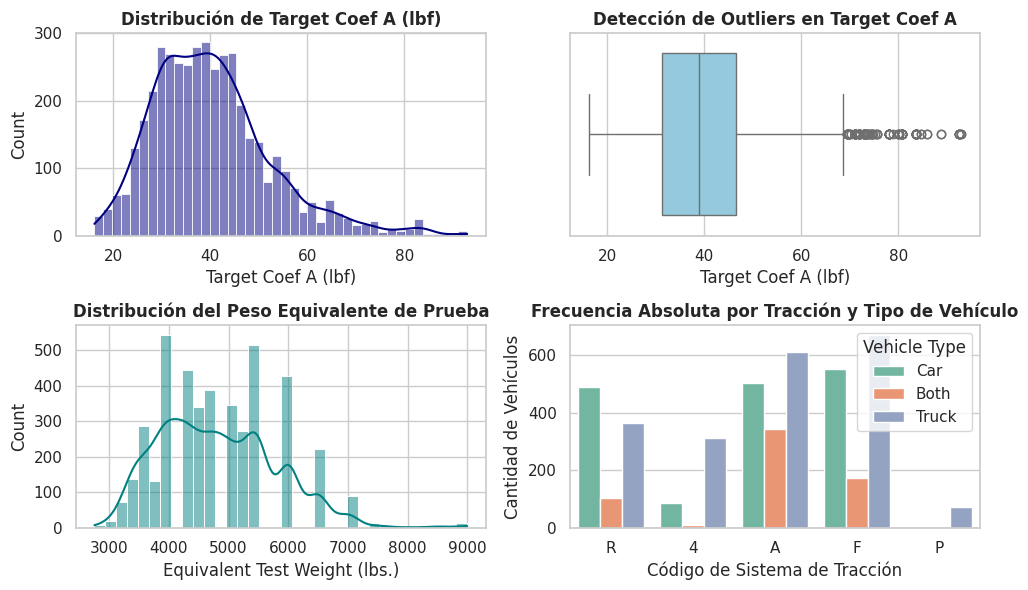

In [220]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tabla de Estadísticos Descriptivos Cuantitativos
print("=== ESTADÍSTICA DESCRIPTIVA: VARIABLES CUANTITATIVAS ===")
stats_num = dataset['h4_df'][[dataset['h4_var_dep'], 'Equivalent Test Weight (lbs.)']].describe().T
stats_num['skewness'] = dataset['h4_df'][[dataset['h4_var_dep'], 'Equivalent Test Weight (lbs.)']].skew()
stats_num['kurtosis'] = dataset['h4_df'][[dataset['h4_var_dep'], 'Equivalent Test Weight (lbs.)']].kurt()
display(stats_num[['mean', 'std', 'min', '50%', 'max', 'skewness', 'kurtosis']])

# 2. Gráfico 1: Distribución Univariada de Target Coef A y Peso Equivalente. Creamos como n dashboard, una matriz de  2x2 en 1 figura
fig, axes = plt.subplots(2, 2)

# Subplot A: Histograma Target Coef A
sns.histplot(data=dataset['h4_df'], x=dataset['h4_var_dep'], kde=True, ax=axes[0,0], color='navy')
axes[0,0].set_title('Distribución de Target Coef A (lbf)', fontweight='bold')
axes[0,0].set_xlabel('Target Coef A (lbf)')

# Subplot B: Boxplot Target Coef A
sns.boxplot(data=dataset['h4_df'], x=dataset['h4_var_dep'], ax=axes[0,1], color='skyblue')
axes[0,1].set_title('Detección de Outliers en Target Coef A', fontweight='bold')
axes[0,1].set_xlabel('Target Coef A (lbf)')

# Subplot C: Histograma Peso Equivalente --> visualización de l avairbailidad de Equivalent Test Weight (lbs.)
sns.histplot(data=dataset['h4_df'], x='Equivalent Test Weight (lbs.)', kde=True, ax=axes[1,0], color='teal')
axes[1,0].set_title('Distribución del Peso Equivalente de Prueba', fontweight='bold')
axes[1,0].set_xlabel('Equivalent Test Weight (lbs.)')

# Subplot D: Frecuencias de Categorías de Tracción
sns.countplot(data=dataset['h4_df'], x='Drive System Code', hue='Vehicle Type', ax=axes[1,1], palette='Set2')
axes[1,1].set_title('Frecuencia Absoluta por Tracción y Tipo de Vehículo', fontweight='bold')
axes[1,1].set_xlabel('Código de Sistema de Tracción')
axes[1,1].set_ylabel('Cantidad de Vehículos')

plt.tight_layout()  #ajusta automáticamente los márgenes y espacios entre los 4 subplots
plt.show()

# el prefijo set, ejemplo axes[].set_title es la sintaxis orientada a objetos de Axes.
# ax=  axes[,] elije el cuadrante de la caja de 2x2 donde se va a posicionar el gráfico

#### Análisis bivariado : Relación Peso (Equivalent Test Weight (lbs.)) vs Target Coef A por Categoría

En el análisis bivariado sabemos que son buenos los scatter plots, para 2 variables cuantitativas

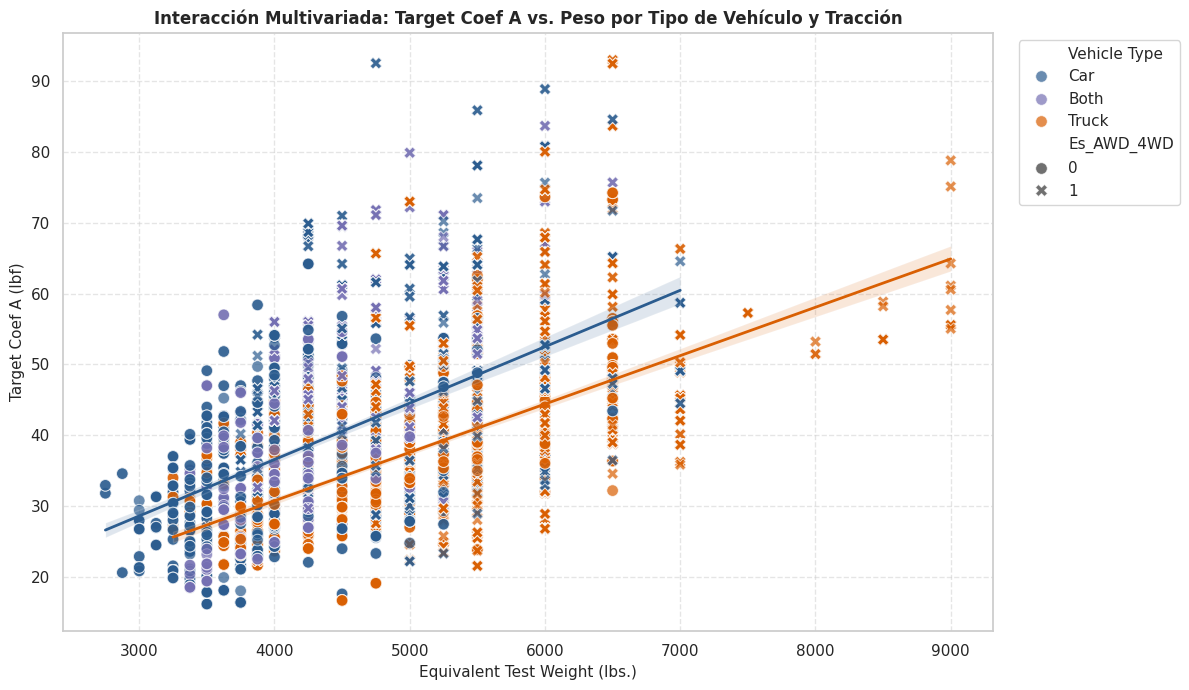

In [222]:
plt.figure(figsize=(12,7))
sns.scatterplot(
    data=dataset['h4_df'],
    x='Equivalent Test Weight (lbs.)',
    y=dataset['h4_var_dep'],
    hue='Vehicle Type',
    style='Es_AWD_4WD',
    alpha=0.7,
    s=70,
    palette={'Car': '#2b5c8f', 'Truck': '#d95f02', 'Both': '#7570b3'}
)

# Ajuste de líneas de tendencia por grupo para evaluar cambios de pendiente
sns.regplot(
    data=dataset['h4_df'][dataset['h4_df']['Vehicle Type'] == 'Car'],
    x='Equivalent Test Weight (lbs.)',
    y=dataset['h4_var_dep'],
    scatter=False,
    color='#2b5c8f',
    line_kws={'label': 'Tendencia Cars', 'linewidth': 2}
)

sns.regplot(
    data=dataset['h4_df'][dataset['h4_df']['Vehicle Type'] == 'Truck'],
    x='Equivalent Test Weight (lbs.)',
    y=dataset['h4_var_dep'],
    scatter=False,
    color='#d95f02',
    line_kws={'label': 'Tendencia Trucks', 'linewidth': 2}
)

plt.title('Interacción Multivariada: Target Coef A vs. Peso por Tipo de Vehículo y Tracción', fontweight='bold', fontsize=12)
plt.xlabel('Equivalent Test Weight (lbs.)', fontsize=11)
plt.ylabel('Target Coef A (lbf)', fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


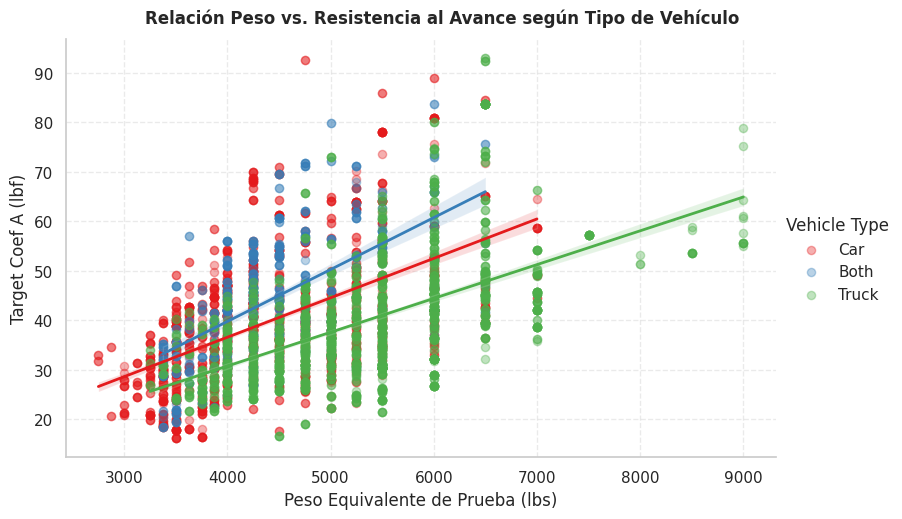

In [223]:
g = sns.lmplot(
    data=dataset['h4_df'],
    x='Equivalent Test Weight (lbs.)',
    y=dataset['h4_var_dep'],
    hue='Vehicle Type',
    palette='Set1',
    height=5,
    aspect=1.6,
    scatter_kws={'alpha': 0.35, 's': 35},  # Transparencia para evitar amontonamiento
    line_kws={'linewidth': 2}
)

# Personalización clara de etiquetas y título
g.set_axis_labels('Peso Equivalente de Prueba (lbs)', 'Target Coef A (lbf)')
g.fig.suptitle('Relación Peso vs. Resistencia al Avance según Tipo de Vehículo', fontweight='bold', y=1.03)
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

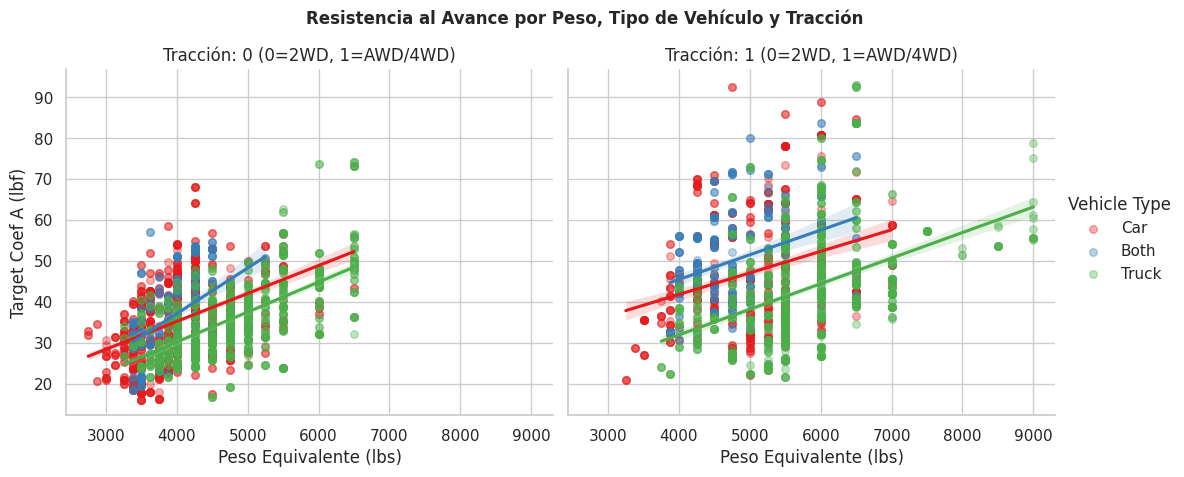

In [224]:
# Faceteado en 2 columnas: 2WD a la izquierda, AWD/4WD a la derecha
g = sns.lmplot(
    data=dataset['h4_df'],
    x='Equivalent Test Weight (lbs.)',
    y=dataset['h4_var_dep'],
    hue='Vehicle Type',
    col='Es_AWD_4WD',  # Separa los paneles por tracción
    palette='Set1',
    height=4.5,
    aspect=1.2,
    scatter_kws={'alpha': 0.35, 's': 30}
)

g.set_axis_labels('Peso Equivalente (lbs)', 'Target Coef A (lbf)')
g.set_titles(col_template="Tracción: {col_name} (0=2WD, 1=AWD/4WD)")
g.fig.suptitle('Resistencia al Avance por Peso, Tipo de Vehículo y Tracción', fontweight='bold', y=1.05)
plt.show()

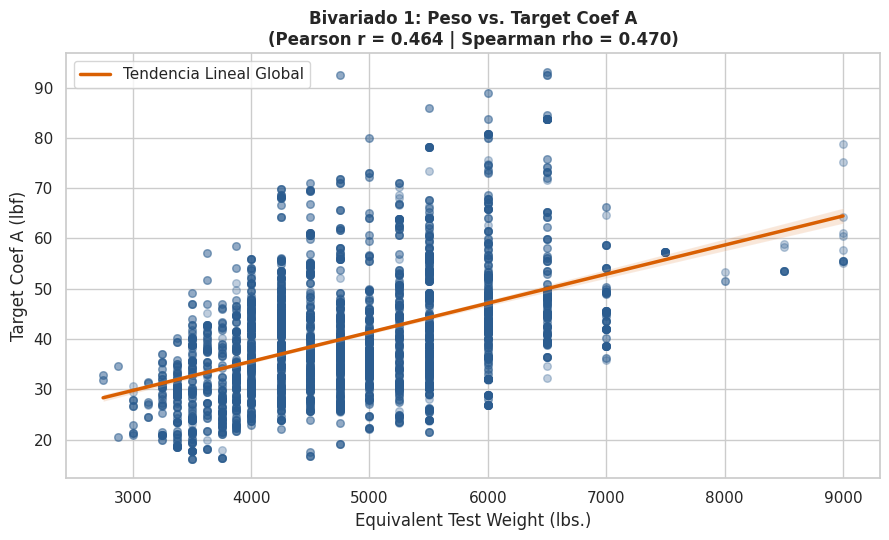

In [225]:
# Gráfico Bivariado 1: Scatter plot simple y Recta de regresión global
plt.figure(figsize=(9, 5.5))

sns.regplot(
    data=dataset['h4_df'],
    x='Equivalent Test Weight (lbs.)',
    y=dataset['h4_var_dep'],
    scatter_kws={'alpha': 0.3, 'color': '#2b5c8f', 's': 30},
    line_kws={'color': '#d95f02', 'linewidth': 2.5, 'label': 'Tendencia Lineal Global'}
)

# Cálculo de correlaciones (Pearson y Spearman)
corr_p = dataset['h4_df']['Equivalent Test Weight (lbs.)'].corr(dataset['h4_df'][dataset['h4_var_dep']], method='pearson')
corr_s = dataset['h4_df']['Equivalent Test Weight (lbs.)'].corr(dataset['h4_df'][dataset['h4_var_dep']], method='spearman')

plt.title(f'Bivariado 1: Peso vs. Target Coef A\n(Pearson r = {corr_p:.3f} | Spearman rho = {corr_s:.3f})', fontweight='bold')
plt.xlabel('Equivalent Test Weight (lbs.)')
plt.ylabel('Target Coef A (lbf)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

ValueError: Could not interpret value `Tipo_Vehiculo_Grupo` for `x`. An entry with this name does not appear in `data`.

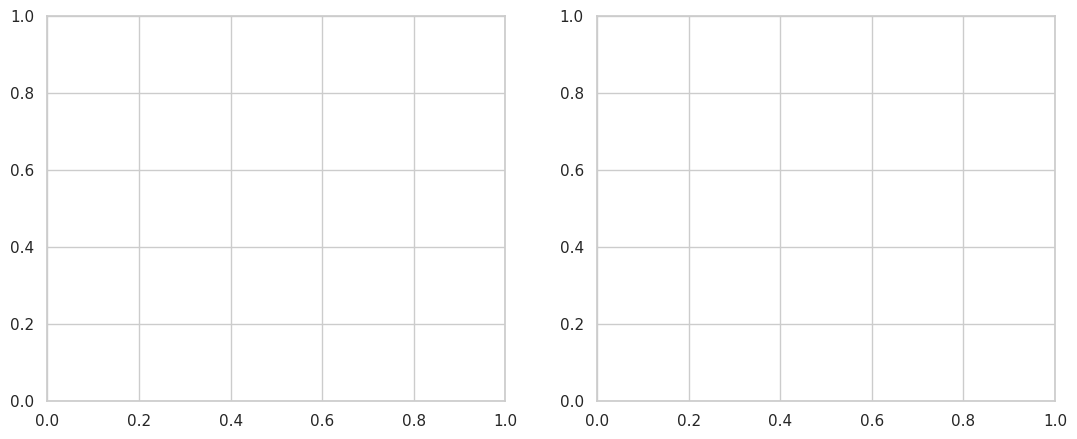

In [226]:
# Gráfico Bivariado 2: Comparación de Car (0) vs. Truck/Both (1)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot A: Boxplot + Stripplot
sns.boxplot(
    data=dataset['h4_df'],
    x='Tipo_Vehiculo_Grupo',
    y=dataset['h4_var_dep'],
    palette=['#3498db', '#e74c3c'],
    ax=axes[0]
)
sns.stripplot(data=dataset['h4_df'], x='Tipo_Vehiculo_Grupo', y=dataset['h4_var_dep'], color='black', alpha=0.15, jitter=0.2, ax=axes[0])
axes[0].set_title('Distribución de Coeficiente A por Tipo de Vehículo', fontweight='bold')
axes[0].set_xlabel('Categoría Consolidada')
axes[0].set_ylabel('Target Coef A (lbf)')

# Subplot B: Histograma de Densidad Superpuesto (KDE)
sns.kdeplot(
    data=dataset['h4_df'],
    x=dataset['h4_var_dep'],
    hue='Tipo_Vehiculo_Grupo',
    common_norm=False,
    fill=True,
    alpha=0.3,
    palette=['#3498db', '#e74c3c'],
    ax=axes[1]
)
axes[1].set_title('Densidad del Coeficiente A (Car vs. Truck/Both)', fontweight='bold')
axes[1].set_xlabel('Target Coef A (lbf)')

plt.tight_layout()
plt.show()

# Estadísticos descriptivos agrupados
print("=== ESTADÍSTICOS DE TARGET COEF A POR TIPO DE VEHÍCULO ===")
display(dataset['h4_df'].groupby('Tipo_Vehiculo_Grupo')[dataset['h4_var_dep']].describe())

## 4. Validación de hipótesis